# 03. Deep Dive — Temporal


## Notebook này làm gì

Phân tích nhịp hoạt động transaction, basket, household và campaign theo thời gian.

### Nội dung đã thực hiện

- Dashboard basket theo ngày, giai đoạn tương đối và giờ giao dịch.
- Phân phối số tuần active và heatmap coverage tuần của household.
- Đếm số dòng transaction theo DAY và WEEK_NO, gồm cả mốc thiếu có giá trị 0.
- Tính độ dài từng campaign từ START_DAY và END_DAY.
- Đếm basket distinct theo day-number và giờ; vẽ heatmap day-number × giờ.
- Day-number dùng quy ước DAY 5 = ngày 7 và DAY 6 = ngày 1 của tuần kế tiếp.


In [1]:
from math import ceil
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from propensity.overview.activity_dashboard import (
    load_transaction_activity_dashboard,
    plot_transaction_activity_dashboard,
)


In [2]:
raw_dir = Path("../data/raw/Dunnhumby")


## 10. Transaction Activity Dashboard

- Giao dịch được đếm theo `BASKET_ID` unique.
- Vì dataset chỉ có chỉ số `DAY`, mỗi chu kỳ 365 ngày được chia tương đối thành 12 tháng để so sánh Năm 1 và Năm 2.
- Khung giờ: Sáng 05–10h, Trưa 11–13h, Chiều 14–17h, Tối 18–04h.
- Độ dài lịch sử household = `max(DAY) - min(DAY) + 1`.

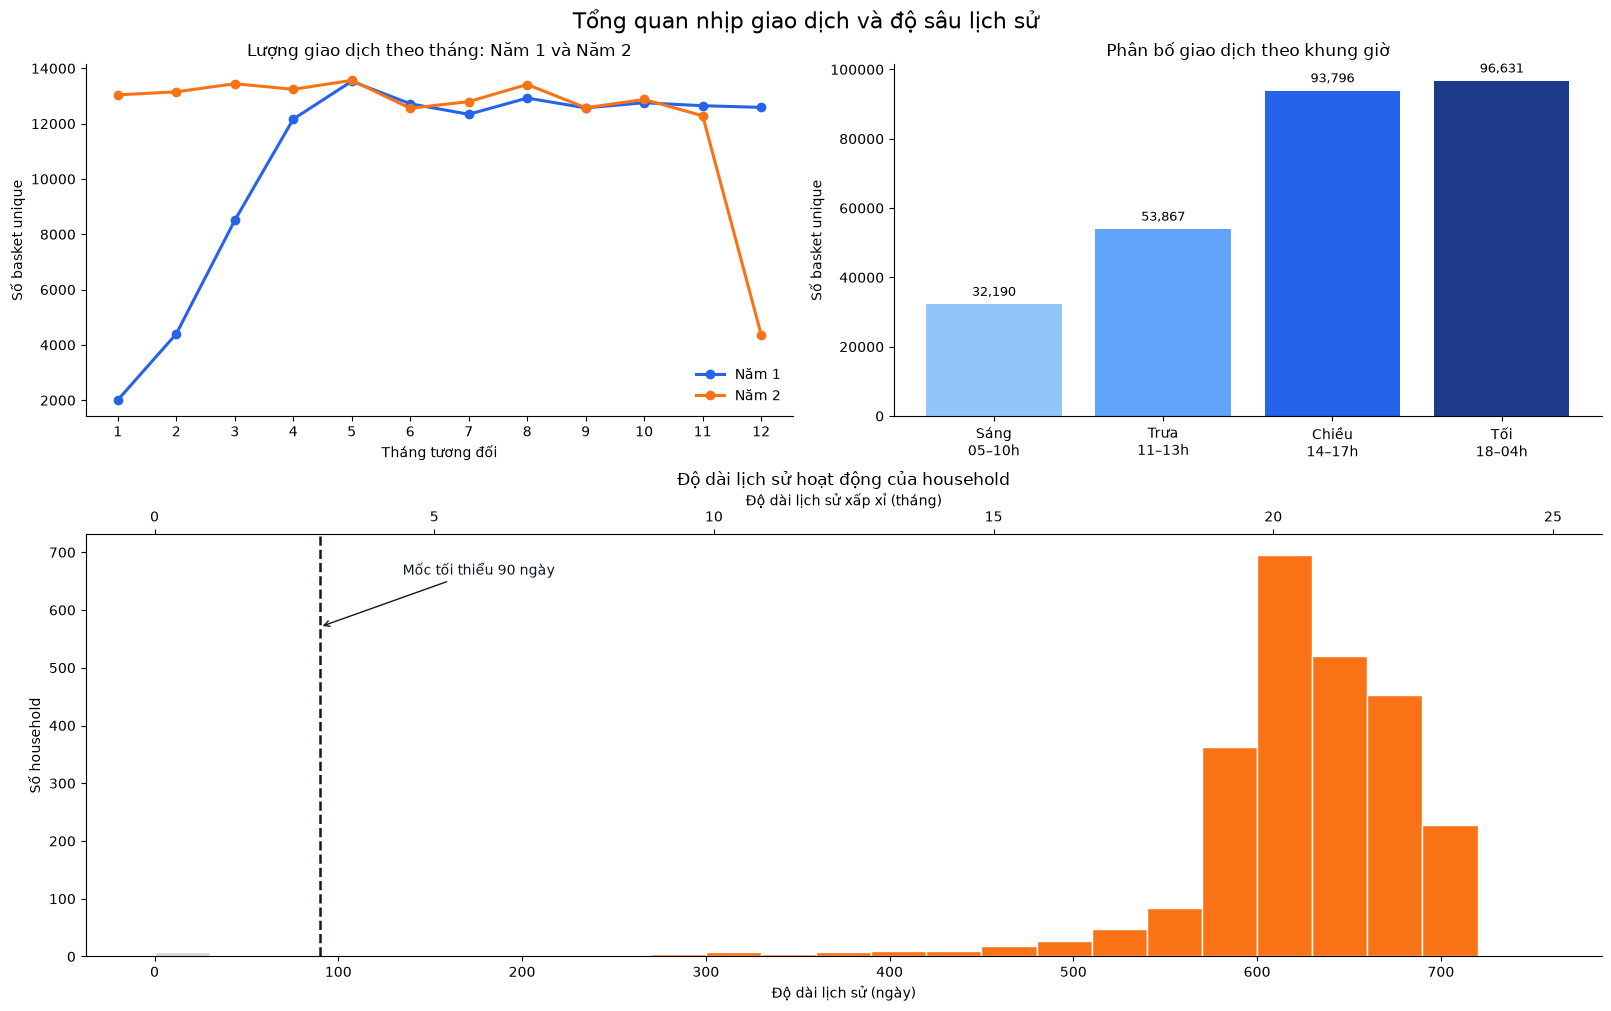

In [3]:
activity_dashboard = load_transaction_activity_dashboard(
    raw_dir / "transaction_data.csv"
)
activity_figure = plot_transaction_activity_dashboard(activity_dashboard)
plt.show()

## 11. Household activity coverage theo tuần

Mỗi ô household × week chứa số `BASKET_ID` distinct. Biểu đồ B dùng toàn bộ household và là biểu đồ ưu tiên để kết luận định lượng. Trong phần thống kê, household "chỉ mua trong vài tuần" được định nghĩa là active không quá 4 tuần.

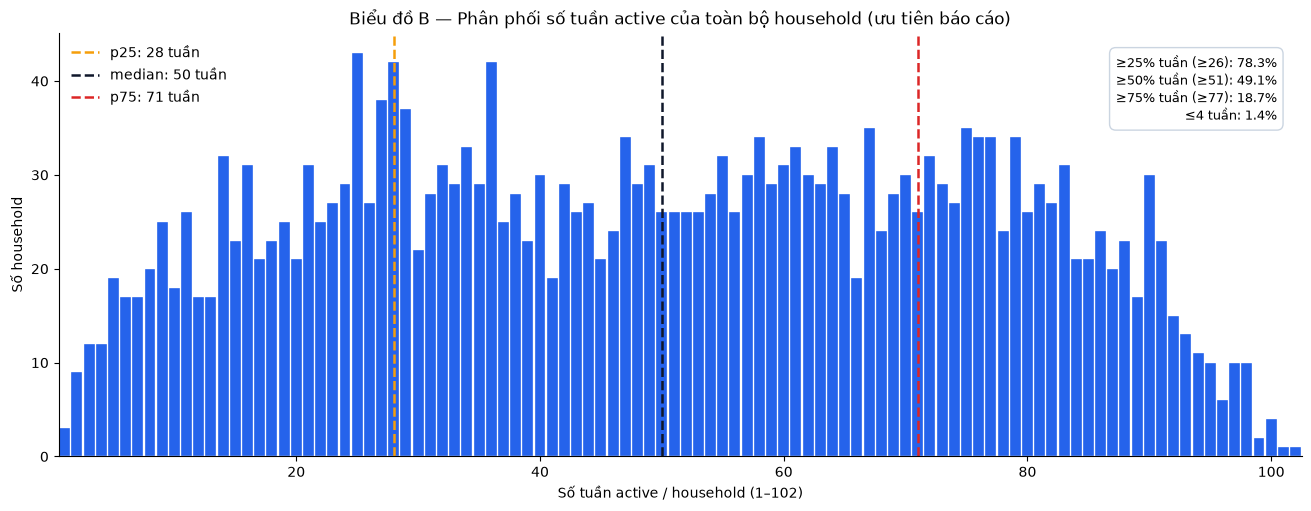

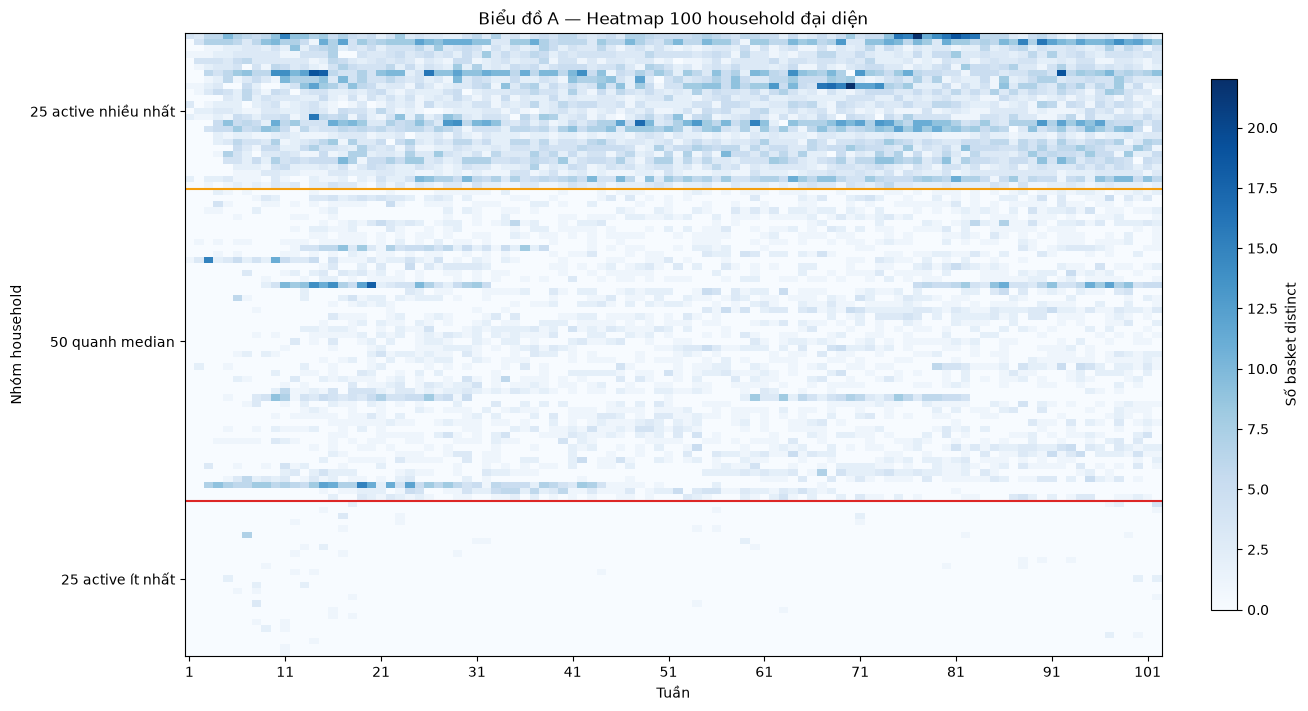

,value
n_households,2500.00
n_observed_weeks,102.00
p25_active_weeks,28.00
median_active_weeks,50.00
p75_active_weeks,71.00
pct_active_at_least_25pct_weeks,78.28
pct_active_at_least_50pct_weeks,49.08
pct_active_at_least_75pct_weeks,18.68
pct_active_at_most_4_weeks,1.44


In [4]:
transaction_baskets = pd.read_csv(
    raw_dir / "transaction_data.csv",
    usecols=["household_key", "BASKET_ID", "DAY", "WEEK_NO", "TRANS_TIME"],
)

coverage_household_week = (
    transaction_baskets
    .dropna(subset=["household_key", "BASKET_ID", "WEEK_NO"])
    .groupby(["household_key", "WEEK_NO"])["BASKET_ID"]
    .nunique()
    .unstack(fill_value=0)
    .sort_index(axis=1)
)
coverage_household_week.columns = [
    f"WEEK_{int(week):03d}" for week in coverage_household_week.columns
]
coverage_household_week.insert(
    0, "active_weeks", coverage_household_week.gt(0).sum(axis=1)
)
coverage_household_week = coverage_household_week.sort_values(
    ["active_weeks", "household_key"], ascending=[False, True]
)
week_columns = [
    column for column in coverage_household_week.columns if column.startswith("WEEK_")
]
n_observed_weeks = len(week_columns)
household_active_weeks = coverage_household_week["active_weeks"]

# Biểu đồ B — toàn bộ household; ưu tiên cho báo cáo.
active_week_quantiles = household_active_weeks.quantile([0.25, 0.50, 0.75])
active_week_quantiles.index = ["p25", "median", "p75"]
activity_thresholds = {
    "25% số tuần quan sát": ceil(n_observed_weeks * 0.25),
    "50% số tuần quan sát": ceil(n_observed_weeks * 0.50),
    "75% số tuần quan sát": ceil(n_observed_weeks * 0.75),
}
active_week_metrics = pd.Series({
    "n_households": int(len(household_active_weeks)),
    "n_observed_weeks": n_observed_weeks,
    "p25_active_weeks": float(active_week_quantiles.loc["p25"]),
    "median_active_weeks": float(active_week_quantiles.loc["median"]),
    "p75_active_weeks": float(active_week_quantiles.loc["p75"]),
    "pct_active_at_least_25pct_weeks": float(
        (household_active_weeks >= activity_thresholds["25% số tuần quan sát"]).mean() * 100
    ),
    "pct_active_at_least_50pct_weeks": float(
        (household_active_weeks >= activity_thresholds["50% số tuần quan sát"]).mean() * 100
    ),
    "pct_active_at_least_75pct_weeks": float(
        (household_active_weeks >= activity_thresholds["75% số tuần quan sát"]).mean() * 100
    ),
    "pct_active_at_most_4_weeks": float(
        (household_active_weeks <= 4).mean() * 100
    ),
}, name="value").to_frame()

active_week_counts = (
    household_active_weeks
    .value_counts()
    .reindex(range(1, n_observed_weeks + 1), fill_value=0)
    .sort_index()
)
activity_distribution_figure, activity_distribution_axis = plt.subplots(
    figsize=(13, 5), layout="constrained"
)
activity_distribution_axis.bar(
    active_week_counts.index,
    active_week_counts.values,
    width=0.9,
    color="#2563EB",
    edgecolor="white",
    linewidth=0.25,
)
for label, color in (("p25", "#F59E0B"), ("median", "#0F172A"), ("p75", "#DC2626")):
    value = float(active_week_quantiles.loc[label])
    activity_distribution_axis.axvline(
        value, color=color, linestyle="--", linewidth=1.8,
        label=f"{label}: {value:g} tuần",
    )
metrics_text = "\n".join([
    f"≥25% tuần (≥{activity_thresholds['25% số tuần quan sát']}): "
    f"{active_week_metrics.loc['pct_active_at_least_25pct_weeks', 'value']:.1f}%",
    f"≥50% tuần (≥{activity_thresholds['50% số tuần quan sát']}): "
    f"{active_week_metrics.loc['pct_active_at_least_50pct_weeks', 'value']:.1f}%",
    f"≥75% tuần (≥{activity_thresholds['75% số tuần quan sát']}): "
    f"{active_week_metrics.loc['pct_active_at_least_75pct_weeks', 'value']:.1f}%",
    f"≤4 tuần: {active_week_metrics.loc['pct_active_at_most_4_weeks', 'value']:.1f}%",
])
activity_distribution_axis.text(
    0.98, 0.95, metrics_text, transform=activity_distribution_axis.transAxes,
    ha="right", va="top", fontsize=9,
    bbox={"boxstyle": "round,pad=0.5", "facecolor": "white", "edgecolor": "#CBD5E1"},
)
activity_distribution_axis.set(
    title="Biểu đồ B — Phân phối số tuần active của toàn bộ household (ưu tiên báo cáo)",
    xlabel=f"Số tuần active / household (1–{n_observed_weeks})",
    ylabel="Số household",
    xlim=(0.5, n_observed_weeks + 0.5),
)
activity_distribution_axis.spines[["top", "right"]].set_visible(False)
activity_distribution_axis.legend(frameon=False)
plt.show()

# Biểu đồ A — 100 household đại diện.
household_activity_rank = (
    coverage_household_week[["active_weeks"]]
    .reset_index()
    .sort_values(["active_weeks", "household_key"], ascending=[False, True])
)
most_active = household_activity_rank.head(25)
least_active = household_activity_rank.tail(25).sort_values(
    ["active_weeks", "household_key"], ascending=[False, True]
)
excluded_households = set(most_active["household_key"]) | set(least_active["household_key"])
median_active_weeks = float(active_week_quantiles.loc["median"])
median_active = (
    household_activity_rank
    .loc[lambda frame: ~frame["household_key"].isin(excluded_households)]
    .assign(distance_to_median=lambda frame: (
        frame["active_weeks"] - median_active_weeks
    ).abs())
    .sort_values(["distance_to_median", "active_weeks", "household_key"])
    .head(50)
    .sort_values(["active_weeks", "household_key"], ascending=[False, True])
)
representative_households = pd.concat(
    [most_active, median_active.drop(columns="distance_to_median"), least_active],
    ignore_index=True,
)
representative_coverage = coverage_household_week.loc[
    representative_households["household_key"], week_columns
]

representative_heatmap_figure, representative_heatmap_axis = plt.subplots(
    figsize=(13, 7), layout="constrained"
)
representative_heatmap_image = representative_heatmap_axis.imshow(
    representative_coverage.to_numpy(dtype="float64"),
    aspect="auto",
    interpolation="nearest",
    cmap="Blues",
)
representative_heatmap_axis.axhline(24.5, color="#F59E0B", linewidth=1.5)
representative_heatmap_axis.axhline(74.5, color="#DC2626", linewidth=1.5)
week_tick_positions = list(range(0, n_observed_weeks, 10))
representative_heatmap_axis.set_xticks(
    week_tick_positions,
    [int(week_columns[position].split("_")[1]) for position in week_tick_positions],
)
representative_heatmap_axis.set_yticks(
    [12, 49, 87],
    ["25 active nhiều nhất", "50 quanh median", "25 active ít nhất"],
)
representative_heatmap_axis.set(
    title="Biểu đồ A — Heatmap 100 household đại diện",
    xlabel="Tuần",
    ylabel="Nhóm household",
)
representative_heatmap_figure.colorbar(
    representative_heatmap_image,
    ax=representative_heatmap_axis,
    label="Số basket distinct",
    shrink=0.85,
)
plt.show()

active_week_metrics

## 12. Số dòng transaction theo ngày và tuần

Dùng line chart vì `DAY` và `WEEK_NO` là trục thời gian có thứ tự. Các ngày hoặc tuần không xuất hiện trong dữ liệu được bổ sung với số dòng bằng 0 để khoảng trống thời gian không bị che khuất.


,by_day,by_week
count,711.000000,102.000000
mean,3650.818565,25448.352941
std,1190.657509,6557.897821
min,2.000000,1881.000000
25%,3167.500000,25808.500000
50%,3713.000000,27202.500000
75%,4324.500000,28731.000000
max,7493.000000,33126.000000


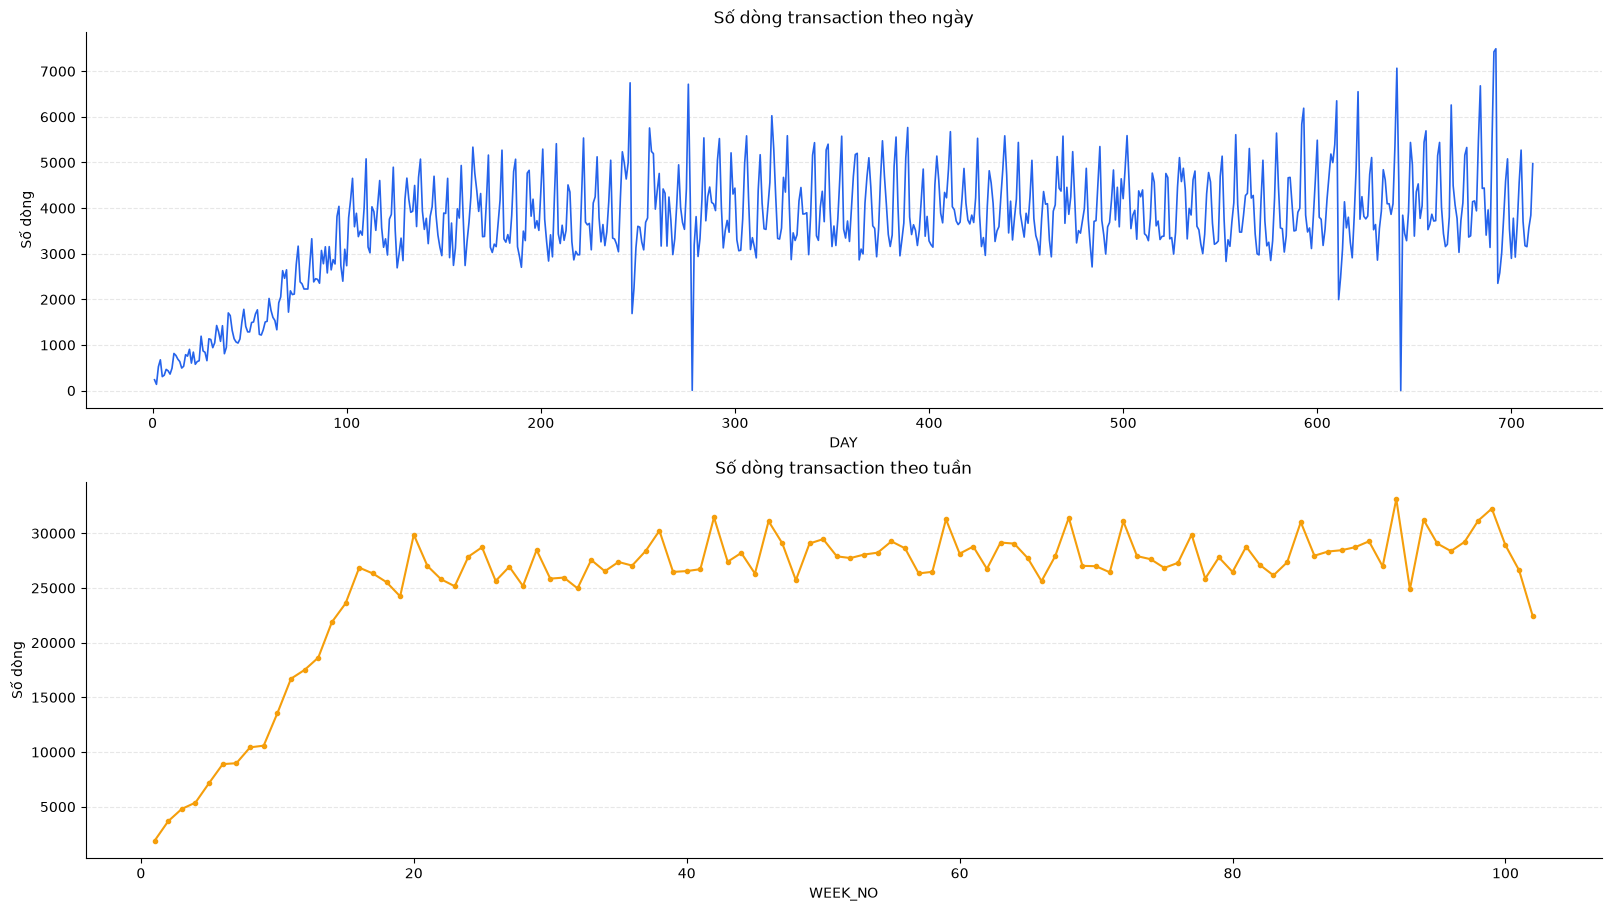

In [5]:
transaction_rows_by_day = (
    transaction_baskets
    .dropna(subset=["DAY"])
    .groupby("DAY")
    .size()
    .reindex(
        range(
            int(transaction_baskets["DAY"].min()),
            int(transaction_baskets["DAY"].max()) + 1,
        ),
        fill_value=0,
    )
    .rename("n_rows")
)
transaction_rows_by_day.index.name = "DAY"

transaction_rows_by_week = (
    transaction_baskets
    .dropna(subset=["WEEK_NO"])
    .groupby("WEEK_NO")
    .size()
    .reindex(
        range(
            int(transaction_baskets["WEEK_NO"].min()),
            int(transaction_baskets["WEEK_NO"].max()) + 1,
        ),
        fill_value=0,
    )
    .rename("n_rows")
)
transaction_rows_by_week.index.name = "WEEK_NO"

transaction_row_counts = pd.concat(
    {
        "by_day": transaction_rows_by_day.describe(),
        "by_week": transaction_rows_by_week.describe(),
    },
    axis=1,
)
display(transaction_row_counts)

transaction_time_figure, transaction_time_axes = plt.subplots(
    2, 1, figsize=(16, 9), layout="constrained"
)
transaction_time_axes[0].plot(
    transaction_rows_by_day.index,
    transaction_rows_by_day.values,
    color="#2563EB",
    linewidth=1.2,
)
transaction_time_axes[0].set(
    title="Số dòng transaction theo ngày",
    xlabel="DAY",
    ylabel="Số dòng",
)
transaction_time_axes[1].plot(
    transaction_rows_by_week.index,
    transaction_rows_by_week.values,
    color="#F59E0B",
    marker="o",
    markersize=3,
    linewidth=1.5,
)
transaction_time_axes[1].set(
    title="Số dòng transaction theo tuần",
    xlabel="WEEK_NO",
    ylabel="Số dòng",
)
for axis in transaction_time_axes:
    axis.spines[["top", "right"]].set_visible(False)
    axis.grid(axis="y", linestyle="--", alpha=0.3)
plt.show()


## 13. Độ dài campaign

Độ dài được tính theo số ngày bao gồm cả ngày bắt đầu và ngày kết thúc: `END_DAY - START_DAY + 1`. Horizontal bar chart phù hợp để so sánh từng campaign và vẫn đọc được đầy đủ nhãn campaign.


,duration_days
count,30.000000
mean,47.600000
std,24.856277
min,33.000000
25%,33.000000
50%,38.500000
75%,55.500000
max,162.000000


,DESCRIPTION,CAMPAIGN,START_DAY,END_DAY,duration_days,campaign_label
0,TypeB,2,351,383,33,Campaign 2 (TypeB)
1,TypeB,4,372,404,33,Campaign 4 (TypeB)
2,TypeC,6,393,425,33,Campaign 6 (TypeC)
3,TypeB,9,435,467,33,Campaign 9 (TypeB)
4,TypeB,10,463,495,33,Campaign 10 (TypeB)
5,TypeB,12,477,509,33,Campaign 12 (TypeB)
6,TypeB,16,561,593,33,Campaign 16 (TypeB)
7,TypeB,17,575,607,33,Campaign 17 (TypeB)
8,TypeB,19,603,635,33,Campaign 19 (TypeB)
9,TypeB,21,624,656,33,Campaign 21 (TypeB)


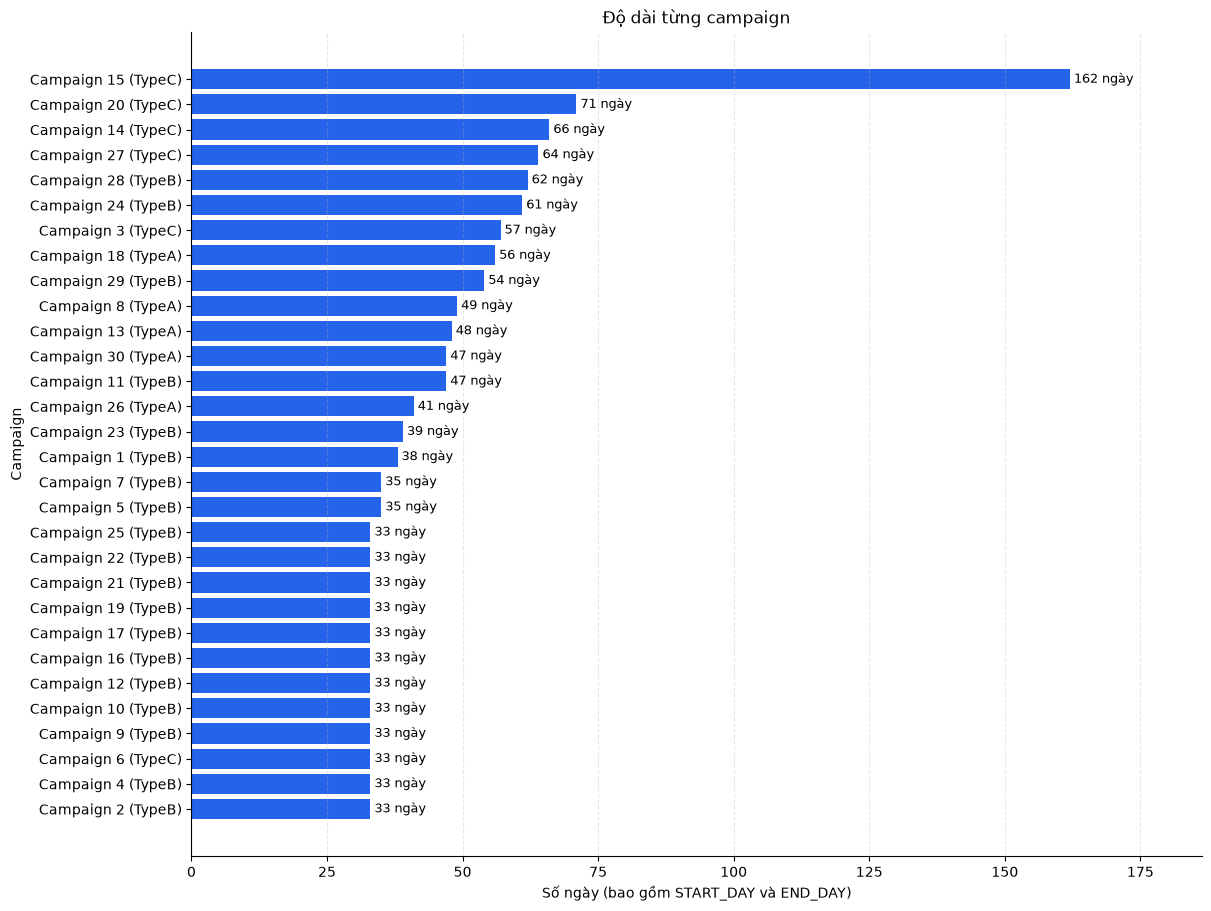

In [6]:
campaign_duration = pd.read_csv(
    raw_dir / "campaign_desc.csv",
    usecols=["DESCRIPTION", "CAMPAIGN", "START_DAY", "END_DAY"],
)
campaign_duration["duration_days"] = (
    campaign_duration["END_DAY"] - campaign_duration["START_DAY"] + 1
)
campaign_duration["campaign_label"] = (
    "Campaign "
    + campaign_duration["CAMPAIGN"].astype("string")
    + " ("
    + campaign_duration["DESCRIPTION"].astype("string")
    + ")"
)
campaign_duration = campaign_duration.sort_values(
    ["duration_days", "CAMPAIGN"], ascending=[True, True]
).reset_index(drop=True)

campaign_duration_summary = (
    campaign_duration["duration_days"]
    .describe(percentiles=[0.25, 0.50, 0.75])
    .rename("duration_days")
    .to_frame()
)
display(campaign_duration_summary, campaign_duration)

campaign_duration_figure, campaign_duration_axis = plt.subplots(
    figsize=(12, 9), layout="constrained"
)
campaign_duration_bars = campaign_duration_axis.barh(
    campaign_duration["campaign_label"],
    campaign_duration["duration_days"],
    color="#2563EB",
)
for bar, duration_days in zip(
    campaign_duration_bars, campaign_duration["duration_days"], strict=True
):
    campaign_duration_axis.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f" {int(duration_days)} ngày",
        va="center",
        fontsize=9,
    )
campaign_duration_axis.set(
    title="Độ dài từng campaign",
    xlabel="Số ngày (bao gồm START_DAY và END_DAY)",
    ylabel="Campaign",
)
campaign_duration_axis.margins(x=0.15)
campaign_duration_axis.spines[["top", "right"]].set_visible(False)
campaign_duration_axis.grid(axis="x", linestyle="--", alpha=0.3)
plt.show()


## 14. Số basket theo day-number trong tuần và giờ

Tuần đầu tiên chỉ quan sát `DAY 1–5`, tương ứng day-number 3–7; `DAY 5` là day-number 7 và tuần thứ hai bắt đầu tại `DAY 6` = day-number 1. Do đó day-number được tính bằng `((DAY + 1) % 7) + 1`. Mỗi `BASKET_ID` chỉ được đếm một lần.


,n_baskets
day_number_in_week,
1,38767
2,36797
3,37026
4,37243
5,38580
6,44120
7,43951


,n_baskets
transaction_hour,
0,2052
1,998
2,1118
3,491
4,372
5,639
6,1850
7,3782
8,5659


transaction_hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
day_number_in_week,,,,,,,,,,,,,,,,,,,,,
1,255,126,151,71,62,80,273,486,789,1025,...,2634,2937,3556,4142,3981,3304,2750,1878,1122,522
2,267,128,163,60,40,97,318,614,796,1098,...,2434,2646,3317,3954,3718,3133,2510,1748,1090,553
3,251,123,131,55,37,111,264,595,749,1030,...,2367,2780,3385,3913,3743,3099,2602,2046,1173,544
4,297,153,171,58,47,114,336,608,835,1064,...,2443,2819,3405,3768,3600,3207,2487,1890,1171,559
5,276,145,141,78,64,95,304,585,852,1088,...,2665,3002,3333,3792,3530,3113,2525,2121,1492,791
6,395,171,206,99,76,84,207,495,912,1490,...,3511,3537,3810,3837,3570,3115,2468,1938,1387,750
7,311,152,155,70,46,58,148,399,726,1432,...,3793,3906,4070,4040,3590,3016,2455,1766,1031,512


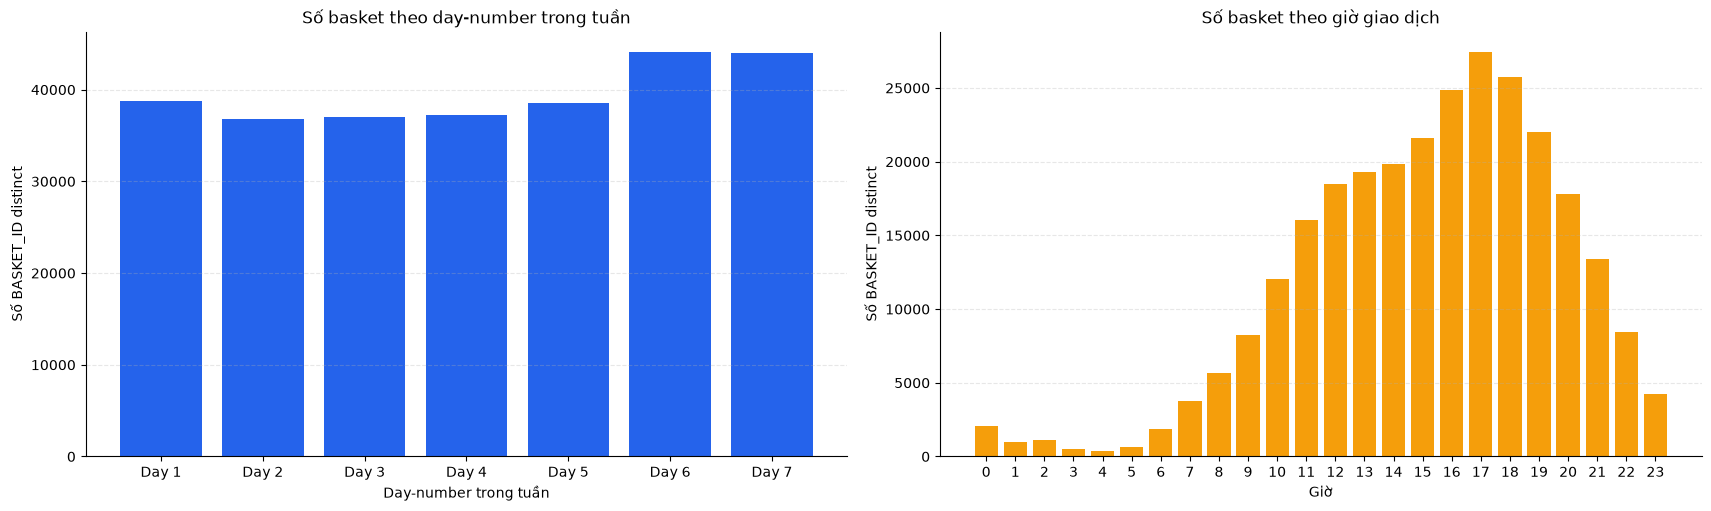

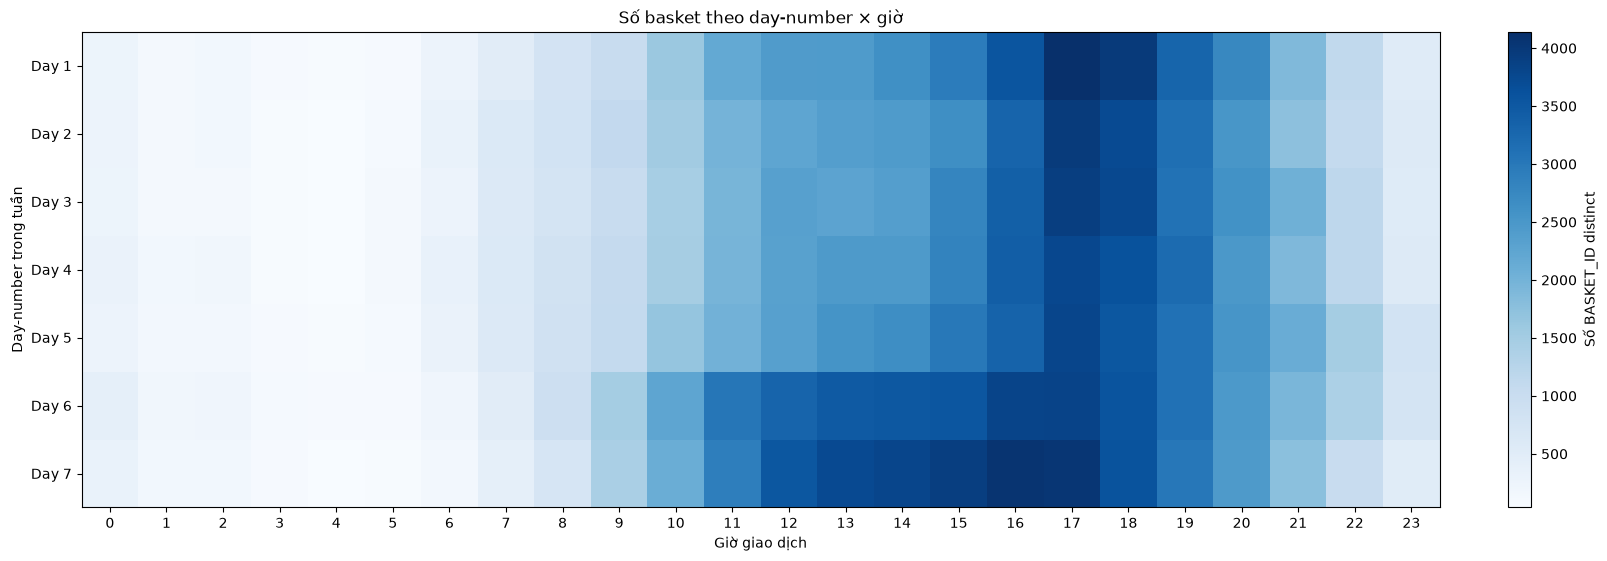

In [7]:
basket_time = (
    transaction_baskets
    .dropna(subset=["BASKET_ID", "DAY", "TRANS_TIME"])
    .drop_duplicates("BASKET_ID")
    .copy()
)
basket_time["DAY"] = pd.to_numeric(basket_time["DAY"], errors="coerce")
basket_time["TRANS_TIME"] = pd.to_numeric(
    basket_time["TRANS_TIME"], errors="coerce"
)
basket_time = basket_time.dropna(subset=["DAY", "TRANS_TIME"])
basket_time["day_number_in_week"] = (
    ((basket_time["DAY"] + 1) % 7) + 1
).astype("int64")
basket_time["transaction_hour"] = (
    basket_time["TRANS_TIME"] // 100
).astype("int64")
basket_time = basket_time.loc[
    basket_time["transaction_hour"].between(0, 23)
]

baskets_by_day_number = (
    basket_time["day_number_in_week"]
    .value_counts()
    .reindex(range(1, 8), fill_value=0)
    .sort_index()
    .rename("n_baskets")
)
baskets_by_hour = (
    basket_time["transaction_hour"]
    .value_counts()
    .reindex(range(24), fill_value=0)
    .sort_index()
    .rename("n_baskets")
)
baskets_by_day_hour = (
    basket_time
    .groupby(["day_number_in_week", "transaction_hour"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=range(1, 8), columns=range(24), fill_value=0)
)

display(
    baskets_by_day_number.to_frame(),
    baskets_by_hour.to_frame(),
    baskets_by_day_hour,
)

basket_time_figure, basket_time_axes = plt.subplots(
    1, 2, figsize=(17, 5), layout="constrained"
)
basket_time_axes[0].bar(
    baskets_by_day_number.index,
    baskets_by_day_number.values,
    color="#2563EB",
)
basket_time_axes[0].set_xticks(
    range(1, 8), [f"Day {day_number}" for day_number in range(1, 8)]
)
basket_time_axes[0].set(
    title="Số basket theo day-number trong tuần",
    xlabel="Day-number trong tuần",
    ylabel="Số BASKET_ID distinct",
)
basket_time_axes[1].bar(
    baskets_by_hour.index,
    baskets_by_hour.values,
    color="#F59E0B",
)
basket_time_axes[1].set_xticks(range(24))
basket_time_axes[1].set(
    title="Số basket theo giờ giao dịch",
    xlabel="Giờ",
    ylabel="Số BASKET_ID distinct",
)
for axis in basket_time_axes:
    axis.spines[["top", "right"]].set_visible(False)
    axis.grid(axis="y", linestyle="--", alpha=0.3)
plt.show()

basket_day_hour_figure, basket_day_hour_axis = plt.subplots(
    figsize=(16, 5.5), layout="constrained"
)
basket_day_hour_image = basket_day_hour_axis.imshow(
    baskets_by_day_hour.to_numpy(dtype="float64"),
    aspect="auto",
    interpolation="nearest",
    cmap="Blues",
)
basket_day_hour_axis.set_xticks(range(24), range(24))
basket_day_hour_axis.set_yticks(
    range(7), [f"Day {day_number}" for day_number in range(1, 8)]
)
basket_day_hour_axis.set(
    title="Số basket theo day-number × giờ",
    xlabel="Giờ giao dịch",
    ylabel="Day-number trong tuần",
)
basket_day_hour_figure.colorbar(
    basket_day_hour_image,
    ax=basket_day_hour_axis,
    label="Số BASKET_ID distinct",
)
plt.show()
